# 01 数据探索：DAS 瀑布图与单通道波形

本 Notebook 提供 DAS 数据读取、瀑布图和单通道波形可视化框架。

- 支持 HDF5 DAS 文件（`data/raw/`）、仿真数据（`data/synthetic/`）以及
  预处理后的窗口（`data/processed/`）。
- 数据约定：单条记录形状为 `(channels, samples)`。
- 若尚无数据，请先在项目根目录运行：

```bash
python scripts/run_preprocess.py --synthetic --overwrite
```


In [1]:
%matplotlib inline

from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import yaml

# 同时支持从项目根目录或 notebooks/ 目录启动 Jupyter。
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_io import HDF5DASReader
from src.dsp import rms_feature
from src.utils import plot_channel_waveform, plot_waterfall

CONFIG_PATH = PROJECT_ROOT / "configs" / "exp_default.yaml"
config = yaml.safe_load(CONFIG_PATH.read_text(encoding="utf-8"))
DATA_DIR = PROJECT_ROOT / "data"
print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)


Project root: D:\DSwork\DAS_Track_Anomaly_Detection
Data directory: D:\DSwork\DAS_Track_Anomaly_Detection\data


## 1. 读取一条示例记录

读取优先级：原始 HDF5 → 仿真 `.npz` → 已处理窗口 `.npz`。
真实采集数据通常包含采样率和通道间距属性，读取器会自动提取。


In [2]:
def load_example_recording():
    """读取第一条可用的 DAS 记录，返回 (data, metadata, path)。"""
    h5_files = []
    for pattern in ("*.h5", "*.hdf5", "*.H5", "*.HDF5"):
        h5_files.extend(sorted((DATA_DIR / "raw").rglob(pattern)))
    if h5_files:
        reader = HDF5DASReader(h5_files[0], orientation="auto")
        data = reader.read(dtype="float32")
        return data, reader.metadata.to_dict(), h5_files[0]

    for folder in ("synthetic", "processed"):
        files = sorted((DATA_DIR / folder).rglob("*.npz"))
        if files:
            with np.load(files[0], allow_pickle=False) as payload:
                data = np.asarray(payload["data"], dtype=np.float32)
                metadata = {}
                if "metadata" in payload:
                    try:
                        metadata = json.loads(str(payload["metadata"]))
                    except json.JSONDecodeError:
                        metadata = {}
                if "sampling_rate_hz" in payload:
                    metadata["sampling_rate_hz"] = float(payload["sampling_rate_hz"][0])
                if "channel_spacing_m" in payload:
                    metadata["channel_spacing_m"] = float(payload["channel_spacing_m"][0])
                return data, metadata, files[0]

    raise FileNotFoundError(
        "未找到数据。请运行 python scripts/run_preprocess.py --synthetic --overwrite，"
        "或将 HDF5 文件放入 data/raw/。"
    )


recording, metadata, source_path = load_example_recording()
sampling_rate_hz = float(
    metadata.get("sampling_rate_hz", config["data"]["sampling_rate_hz"])
)
channel_spacing_m = float(
    metadata.get("channel_spacing_m", config["data"]["spatial_spacing_m"])
)
print("Source:", source_path)
print("Shape (channels, samples):", recording.shape)
print("Sampling rate (Hz):", sampling_rate_hz)
print("Channel spacing (m):", channel_spacing_m)


Source: D:\DSwork\DAS_Track_Anomaly_Detection\data\synthetic\test\test_anomaly_0000.npz
Shape (channels, samples): (96, 8000)
Sampling rate (Hz): 1000.0
Channel spacing (m): 0.5


In [3]:
duration_s = recording.shape[1] / sampling_rate_hz
print(f"Channels: {recording.shape[0]}")
print(f"Samples: {recording.shape[1]} ({duration_s:.3f} s)")
print(f"Amplitude range: [{recording.min():.4g}, {recording.max():.4g}]")
print(f"Mean / std: {recording.mean():.4g} / {recording.std():.4g}")
print("Metadata keys:", sorted(metadata.keys()))


Channels: 96
Samples: 8000 (8.000 s)
Amplitude range: [-1.24, 1.347]
Mean / std: -2.386e-06 / 0.1195
Metadata keys: ['anomaly', 'anomaly_channels', 'channel_spacing_m', 'defect', 'duration_s', 'n_channels', 'n_samples', 'sampling_rate_hz', 'simulation', 'source', 'speed_mps']


## 2. 瀑布图

瀑布图的横轴为时间、纵轴为沿光纤距离、颜色为振动幅值。绘制时使用
稳健分位数裁剪色标，避免个别强脉冲压扁整体动态范围。


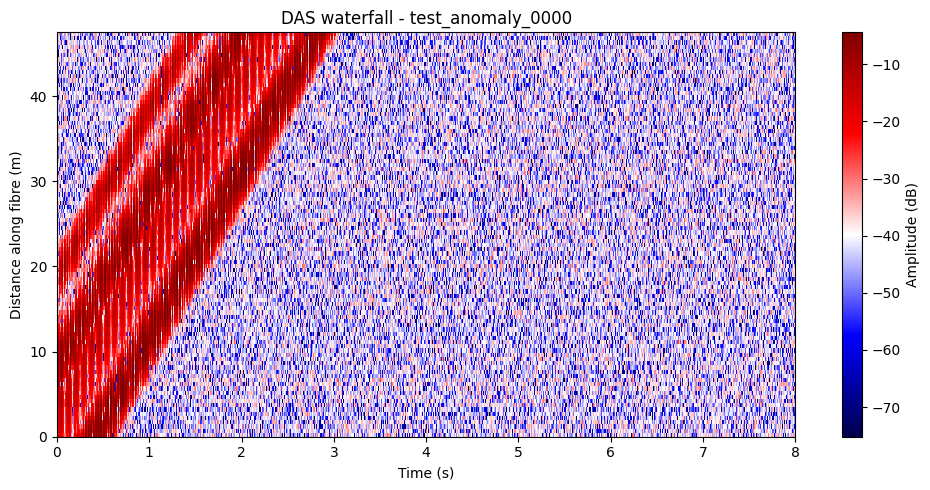

In [4]:
fig, ax = plot_waterfall(
    recording,
    sampling_rate_hz=sampling_rate_hz,
    channel_spacing_m=channel_spacing_m,
    to_db=True,
    title=f"DAS waterfall - {source_path.stem}",
)
plt.show()


## 3. 单通道波形

先按通道 RMS 自动选择能量最强的通道，再绘制其波形。实际分析时可替换为
指定通道，或叠加多个通道进行对比。


Selected channel: 63
Channel RMS: 0.07433


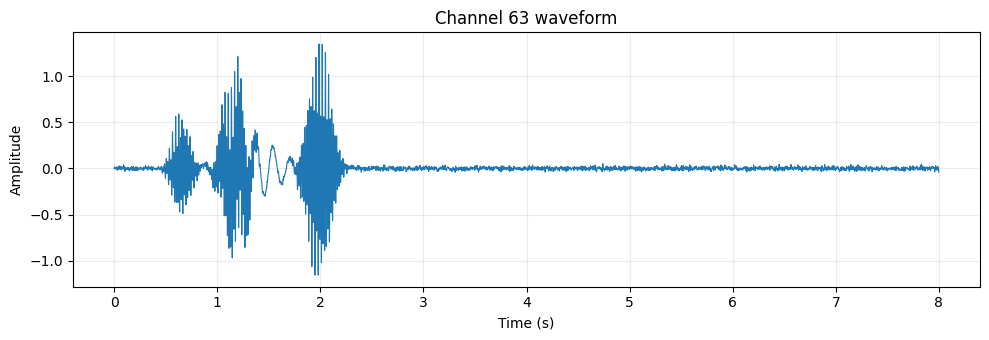

In [5]:
frame_length = min(int(config["data"]["time_window_tw"]), recording.shape[1])
hop_length = max(frame_length // 2, 1)
rms_by_channel = rms_feature(
    recording, frame_length=frame_length, hop_length=hop_length
).mean(axis=1)
selected_channel = int(np.argmax(rms_by_channel))
print(f"Selected channel: {selected_channel}")
print(f"Channel RMS: {rms_by_channel[selected_channel]:.4g}")

fig, ax = plot_channel_waveform(
    recording,
    channel=selected_channel,
    sampling_rate_hz=sampling_rate_hz,
    title=f"Channel {selected_channel} waveform",
)
plt.show()


## 4. 空间 RMS 分布

该曲线可用于快速定位耦合异常或高噪声区段。


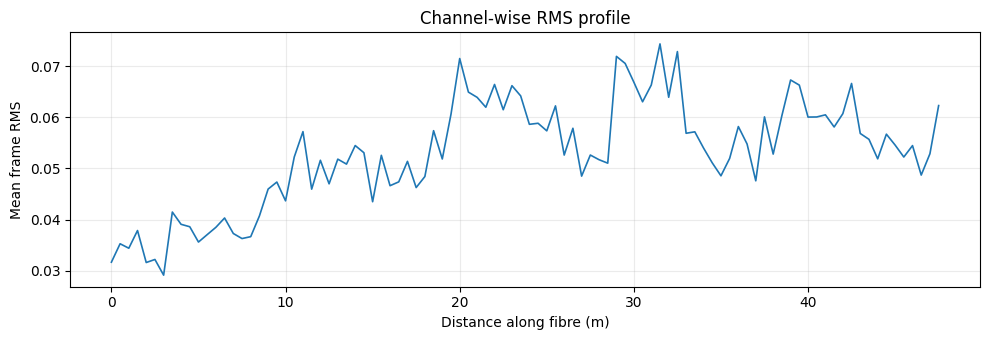

In [6]:
distance_m = np.arange(recording.shape[0]) * channel_spacing_m
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(distance_m, rms_by_channel, linewidth=1.2)
ax.set_xlabel("Distance along fibre (m)")
ax.set_ylabel("Mean frame RMS")
ax.set_title("Channel-wise RMS profile")
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


## 下一步

- 打开 `02_filter_and_stft_test.ipynb` 比较滤波前后的时频结构。
- 打开 `03_residual_analysis.ipynb` 查看模型重构残差和异常打分。
- 将所有绘图函数中的 `recording` 换成自己的数据即可复用。
